In [1]:
#!pip install --user antspyx

In [2]:
import sys
import os
import os.path as op
import glob
import nibabel as nib

# Make utils.py (lab helpers) importable
notebook_dir = os.path.abspath("")
sys.path.append(os.path.abspath(os.path.join(notebook_dir, '..')))
sys.path.append('.')
from utils import loadFSL, FSLeyesServer

# Load FSL in Neurodesk
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

from fsl.wrappers import fast, flirt

In [3]:
from nilearn import plotting
fig_dir = op.abspath("outputs/figures")
os.makedirs(fig_dir, exist_ok=True)

In [4]:
%gui wx


(ipykernel_launcher.py:3417): dbind-WARNING **: 12:47:18.578: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203552428/at-spi/bus_100: No such file or directory


In [5]:
################
# Start FSLeyes
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

12:47:19: Debug: Adding duplicate image handler for 'Windows bitmap file'
12:47:19: Debug: Adding duplicate animation handler for '1' type
12:47:19: Debug: Adding duplicate animation handler for '2' type
12:47:19: Debug: Adding duplicate image handler for 'Windows bitmap file'
12:47:19: Debug: Adding duplicate animation handler for '1' type
12:47:19: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:3417): Gtk-CRITICAL **: 12:47:20.027: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:3417): Gtk-CRITICAL **: 12:47:21.896: gtk_window_resize: assertion 'width > 0' failed


In [6]:
t1_path = op.abspath("miniproject_2026_final/T1/T1w.nii.gz")
print(t1_path, op.isfile(t1_path)) 

/data/Desktop/myfiles/NX421_project1/miniproject_2026_final/T1/T1w.nii.gz True


In [7]:
# Visual check of the raw T1w
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)

## 1.1 Skull stripping

In [8]:
def get_skull_stripped_anatomical(anatomical_path, output_dir, robust=True):
    # -R: robust center estimation, avoids leaving neck tissue
    os.makedirs(output_dir, exist_ok=True)
    betted_brain_path = op.join(output_dir, 'T1w')
    os.system('bet {} {} -m {}'.format(anatomical_path, betted_brain_path, '-R' if robust else ''))
    print("Done with BET.")

# paths
anatomical_path = op.abspath("miniproject_2026_final/T1/T1w.nii.gz") #path to the T1w image
output_dir = op.abspath("outputs/anat") #where the results are saved

get_skull_stripped_anatomical(anatomical_path, output_dir)

resulting_mask_path = op.join(output_dir, 'T1w_mask')

Done with BET.


In [9]:
fsleyesDisplay.load(resulting_mask_path)

In [10]:
def apply_python_mask_approach(img_path, mask_path, masked_img_path):

    # Load both the T1 and the mask from disk
    img = nib.load(img_path)
    mask = nib.load(mask_path)
    
    # Load the data from both above images as numpy arrays
    img_data = img.get_fdata()
    mask_data = mask.get_fdata()
    
    # In all positions OUTSIDE the mask (equal to 0), throw away the image
    img_data[mask_data == 0] = 0
    
    # Save the image to disk, by creating a new Nifti image and then writing it out
    img_out = nib.Nifti1Image(img_data,img.affine, img.header)
    nib.save(img_out, masked_img_path)

betted_brain_path = op.join(output_dir, 'T1w_masked.nii.gz') 
resulting_mask_path = op.join(output_dir, 'T1w_mask.nii.gz') # The mask to use

apply_python_mask_approach(anatomical_path, resulting_mask_path, betted_brain_path)

In [11]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)

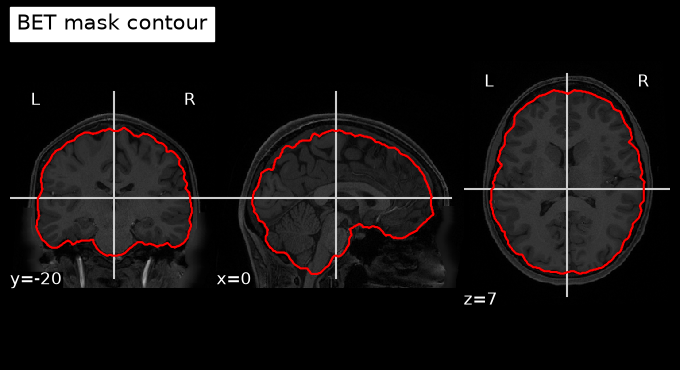

In [12]:
# 1a: original vs skull-stripped, with the mask contour on the original
plotting.plot_anat(anatomical_path, title='Original T1w',
                   output_file=op.join(fig_dir, 'T1w_original.png'))
d = plotting.plot_anat(anatomical_path, title='BET mask contour')
d.add_contours(resulting_mask_path, levels=[0.5], colors='r')
d.savefig(op.join(fig_dir, 'T1w_bet_contour.png'))
plotting.plot_anat(betted_brain_path, title='Skull-stripped T1w',
                   output_file=op.join(fig_dir, 'T1w_skullstripped.png'))

## 1.2 Tissue segmentation

In [ ]:
# FAST is applied to the skull-stripped brain: skull and scalp would otherwise be classified as tissue.
fast_target = betted_brain_path   

[os.remove(f) for f in glob.glob(op.join(output_dir, '*fast*'))] # Just to clean the directory in between runs of the cell
segmentation_path = op.join(output_dir, 'T1w_fast')
# n_classes=3 -> CSF, grey matter, white matter (pve_0, pve_1, pve_2)
fast(imgs=[fast_target], out=segmentation_path, n_classes=3)

In [ ]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain_path)
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_0*'))[0])
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_1*'))[0])
fsleyesDisplay.load(glob.glob(op.join(output_dir, '*pve_2*'))[0])
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

In [ ]:
# 1b: hard segmentation (1=CSF, 2=GM, 3=WM) on the brain
plotting.plot_roi(op.join(output_dir, 'T1w_fast_seg.nii.gz'),
                  bg_img=betted_brain_path, title='FAST segmentation',
                  display_mode='z', cut_coords=6, cmap='Set1',
                  output_file=op.join(fig_dir, 'T1w_segmentation.png'))

## 1.3 Registration

In [ ]:
#from fsl.wrappers import flirt

subject_anatomical = betted_brain_path
mni_template = op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm_brain'))

  # Source = subject T1w (moved), reference = MNI152 1mm brain template (fixed).
  # We map the subject to the template so results can be compared in standard space.

source = subject_anatomical 
reference = mni_template
result = op.join(output_dir, 'T1w_mni')
flirt(source, reference, out=result)

Flirt vizualisation : 

In [ ]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(reference) 
fsleyesDisplay.load(result)

Choosing a cost:

In [ ]:
# Same modality (T1w -> T1w template): within-modality intensity-based costs (leastsq, normcorr)
costs = [ 'leastsq', 'normcorr' ] 

for c in costs:
    flirt(source, reference, out=result + '_' + c, cost=c)

In [ ]:
# Before/after: compare the subject T1w and the MNI template overlay
for c in costs:
    fsleyesDisplay.load(result + '_' + c)

In [ ]:
#from nilearn import plotting
mni_path = mni_template + '.nii.gz'
cuts = (0, -20, 10)   # x, y, z in mm, identical for all panels

images = {
    'Before registration': betted_brain_path,
    'After - corratio (default)': op.join(output_dir, 'T1w_mni.nii.gz'),
    'After - leastsq': op.join(output_dir, 'T1w_mni_leastsq.nii.gz'),
    'After - normcorr': op.join(output_dir, 'T1w_mni_normcorr.nii.gz'),
}

for title, path in images.items():
    d = plotting.plot_anat(path, title=title, cut_coords=cuts)
    d.add_edges(mni_path)

In [ ]:
final_cost = 'normcorr'   # the one we keep
mat_path = op.join(output_dir, 'T1w_to_MNI.mat')
flirt(source, reference, out=op.join(output_dir, 'T1w_mni_final'),
      cost=final_cost, omat=mat_path)

In [ ]:
for name, interp in [('seg', 'nearestneighbour'),
                     ('pve_0', 'trilinear'), ('pve_1', 'trilinear'), ('pve_2', 'trilinear')]:
    flirt(op.join(output_dir, f'T1w_fast_{name}.nii.gz'), reference,
          out=op.join(output_dir, f'T1w_fast_{name}_mni'),
          applyxfm=True, init=mat_path, interp=interp)

In [ ]:
# List outputs to check all files were created
!ls -lh {output_dir}